# AquaGuard AI — Operational and Business KPI Evaluation
**Task:** Comprehensive Operational, Hydraulic, and Economic Assessment of All Six Trained Models  
**Models Evaluated:**
- **Anomaly Detection:** Isolation Forest, Local Outlier Factor, One-Class SVM
- **Leak Identification:** XGBoost Classifier, Random Forest Classifier, Extra Trees Classifier

---
### Evaluation Pillars:
1. **Accuracy & Detection Quality:** F1, Precision, Recall, False-Positive Rate (FPR), Event Detection Rate.
2. **Deterministic Groundedness:** Rule-based verification of diagnostic explanation claims against physical measurements.
3. **Latency Benchmarking:** Single-sample Average, Median, P95, and 1,000-sample Batch throughput.
4. **Computational Cost:** Model artifacts, training duration, and cloud inferencing economics.
5. **Operational Task-Success:** Event-level mission success (capturing events while suppressing false alarms on legitimate demand).
6. **Hydraulic Recovery Lifecycle Simulation:** End-to-end simulated timeline from pipe rupture to valve isolation and stabilization.
7. **Business KPIs & Water Balance:** Campus consumption, zone-wise loss, saved water volume, and financial savings with configurable tariffs.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time
import os
import sys

sys.path.append(os.path.abspath('..'))
sys.path.append(os.path.abspath('.'))

from src.data_loader import load_raw_data, split_dataset_event_aware, ABNORMAL_CANDIDATE_FEATURES, LEAK_CANDIDATE_FEATURES
from src.groundedness import compute_groundedness_score
from src.recovery_simulation import simulate_cohort_recovery
from src.business_kpis import compute_water_balance_metrics, DEFAULT_WATER_TARIFF_PER_M3

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

os.makedirs('../results/figures', exist_ok=True)
os.makedirs('results/figures', exist_ok=True)


## 1. Load Test Partitions and Trained Model Pipelines
We load the untouched test partitions (15% chronological split) and restore all six saved model artifacts.


In [2]:
df_abn, df_leak = load_raw_data()
split_abn = split_dataset_event_aware(df_abn, train_ratio=0.70, val_ratio=0.15)
split_lk = split_dataset_event_aware(df_leak, train_ratio=0.70, val_ratio=0.15)

test_abn = split_abn['test']
test_lk = split_lk['test']

print(f"Test Datasets: Abnormal={test_abn.shape}, Leak={test_lk.shape}")

# Load models
base_model_dir = '../models' if os.path.exists('../models') else 'models'

iso_artifact = joblib.load(os.path.join(base_model_dir, 'anomaly', 'isolation_forest.joblib'))
lof_artifact = joblib.load(os.path.join(base_model_dir, 'anomaly', 'lof.joblib'))
ocsvm_artifact = joblib.load(os.path.join(base_model_dir, 'anomaly', 'one_class_svm.joblib'))

xgb_artifact = joblib.load(os.path.join(base_model_dir, 'leak', 'xgboost_classifier.joblib'))
rf_artifact = joblib.load(os.path.join(base_model_dir, 'leak', 'random_forest.joblib'))
et_artifact = joblib.load(os.path.join(base_model_dir, 'leak', 'extra_trees.joblib'))

print("All 6 model artifacts restored successfully!")


Test Datasets: Abnormal=(46656, 20), Leak=(46656, 19)


All 6 model artifacts restored successfully!


## 2. Generate Test Inferences
Applying trained preprocessing pipelines and decision thresholds.


In [3]:
# Preprocess test inputs
X_abn_proc = iso_artifact['preprocessor'].transform(test_abn[ABNORMAL_CANDIDATE_FEATURES])
X_lk_proc = xgb_artifact['preprocessor'].transform(test_lk[LEAK_CANDIDATE_FEATURES])

# 1. Isolation Forest
iso_scores = -iso_artifact['model'].decision_function(X_abn_proc)
iso_preds = (iso_scores >= iso_artifact['threshold']).astype(int)

# 2. LOF
lof_scores = -lof_artifact['model'].decision_function(X_abn_proc)
lof_preds = (lof_scores >= lof_artifact['threshold']).astype(int)

# 3. OC-SVM
ocsvm_scores = -ocsvm_artifact['model'].decision_function(X_abn_proc)
ocsvm_preds = (ocsvm_scores >= ocsvm_artifact['threshold']).astype(int)

# 4. XGBoost
xgb_preds = xgb_artifact['model'].predict(X_lk_proc)

# 5. Random Forest
rf_preds = rf_artifact['model'].predict(X_lk_proc)

# 6. Extra Trees
et_preds = et_artifact['model'].predict(X_lk_proc)

print("Predictions generated for all 6 models across test sets.")


Predictions generated for all 6 models across test sets.


## 3. Groundedness Evaluation
We evaluate the physical groundedness of alert explanations:
$$\text{Groundedness} = \frac{\text{Supported Explanation Claims}}{\text{Total Explanation Claims}}$$
Tested across a sample of 2,000 predictions using deterministic domain evidence (flow deviations, pressure drops, occupancy, scheduled event tracking).
*Note: This is a deterministic rule-based verification metric, not an LLM hallucination score.*


In [4]:
sample_size = 2000
np.random.seed(42)
idx_abn = np.random.choice(len(test_abn), size=sample_size, replace=False)
idx_lk = np.random.choice(len(test_lk), size=sample_size, replace=False)

g_iso = compute_groundedness_score(test_abn.iloc[idx_abn], iso_preds[idx_abn], is_leak_model=False)
g_lof = compute_groundedness_score(test_abn.iloc[idx_abn], lof_preds[idx_abn], is_leak_model=False)
g_ocsvm = compute_groundedness_score(test_abn.iloc[idx_abn], ocsvm_preds[idx_abn], is_leak_model=False)

g_xgb = compute_groundedness_score(test_lk.iloc[idx_lk], xgb_preds[idx_lk], is_leak_model=True)
g_rf = compute_groundedness_score(test_lk.iloc[idx_lk], rf_preds[idx_lk], is_leak_model=True)
g_et = compute_groundedness_score(test_lk.iloc[idx_lk], et_preds[idx_lk], is_leak_model=True)

groundedness_results = {
    'Isolation Forest': g_iso,
    'Local Outlier Factor': g_lof,
    'One-Class SVM': g_ocsvm,
    'XGBoost': g_xgb,
    'Random Forest': g_rf,
    'Extra Trees': g_et
}

for m, score in groundedness_results.items():
    print(f"  {m:25s}: Groundedness = {score:.4f} ({score*100:.2f}%)")


  Isolation Forest         : Groundedness = 0.9990 (99.90%)
  Local Outlier Factor     : Groundedness = 0.9975 (99.75%)
  One-Class SVM            : Groundedness = 0.9975 (99.75%)
  XGBoost                  : Groundedness = 0.9960 (99.60%)
  Random Forest            : Groundedness = 0.9965 (99.65%)
  Extra Trees              : Groundedness = 0.9798 (97.98%)


## 4. Hydraulic Recovery Lifecycle Simulation
We simulate the operational lifecycle under identical standardized intervention assumptions:
1. Leak begins ($t_{\text{start}}$)
2. Model detects leak ($t_{\text{detect}}$)
3. Automated alert generated ($+2$ min)
4. Recommendation issued ($+3$ min)
5. Operator acknowledgment & dispatch ($+15$ min)
6. Pipe repair / isolation valve shutoff ($+60$ min)
7. Stabilization of hydraulic pressure ($+10$ min)


In [5]:
rec_iso = simulate_cohort_recovery(test_abn, iso_preds, is_leak_model=False)
rec_lof = simulate_cohort_recovery(test_abn, lof_preds, is_leak_model=False)
rec_ocsvm = simulate_cohort_recovery(test_abn, ocsvm_preds, is_leak_model=False)

rec_xgb = simulate_cohort_recovery(test_lk, xgb_preds, is_leak_model=True)
rec_rf = simulate_cohort_recovery(test_lk, rf_preds, is_leak_model=True)
rec_et = simulate_cohort_recovery(test_lk, et_preds, is_leak_model=True)

rec_summary = pd.DataFrame([
    {'Model': 'Isolation Forest', 'Task': 'Anomaly', 'Time to Detection (min)': rec_iso['avg_time_to_detection_mins'], 'Time to Rec (min)': rec_iso['avg_time_to_recommendation_mins'], 'Total Recovery Time (min)': rec_iso['avg_total_recovery_time_mins'], 'Water Saved Ratio': rec_iso['avg_water_saved_ratio']},
    {'Model': 'Local Outlier Factor', 'Task': 'Anomaly', 'Time to Detection (min)': rec_lof['avg_time_to_detection_mins'], 'Time to Rec (min)': rec_lof['avg_time_to_recommendation_mins'], 'Total Recovery Time (min)': rec_lof['avg_total_recovery_time_mins'], 'Water Saved Ratio': rec_lof['avg_water_saved_ratio']},
    {'Model': 'One-Class SVM', 'Task': 'Anomaly', 'Time to Detection (min)': rec_ocsvm['avg_time_to_detection_mins'], 'Time to Rec (min)': rec_ocsvm['avg_time_to_recommendation_mins'], 'Total Recovery Time (min)': rec_ocsvm['avg_total_recovery_time_mins'], 'Water Saved Ratio': rec_ocsvm['avg_water_saved_ratio']},
    {'Model': 'XGBoost', 'Task': 'Leak', 'Time to Detection (min)': rec_xgb['avg_time_to_detection_mins'], 'Time to Rec (min)': rec_xgb['avg_time_to_recommendation_mins'], 'Total Recovery Time (min)': rec_xgb['avg_total_recovery_time_mins'], 'Water Saved Ratio': rec_xgb['avg_water_saved_ratio']},
    {'Model': 'Random Forest', 'Task': 'Leak', 'Time to Detection (min)': rec_rf['avg_time_to_detection_mins'], 'Time to Rec (min)': rec_rf['avg_time_to_recommendation_mins'], 'Total Recovery Time (min)': rec_rf['avg_total_recovery_time_mins'], 'Water Saved Ratio': rec_rf['avg_water_saved_ratio']},
    {'Model': 'Extra Trees', 'Task': 'Leak', 'Time to Detection (min)': rec_et['avg_time_to_detection_mins'], 'Time to Rec (min)': rec_et['avg_time_to_recommendation_mins'], 'Total Recovery Time (min)': rec_et['avg_total_recovery_time_mins'], 'Water Saved Ratio': rec_et['avg_water_saved_ratio']},
])

display(rec_summary)


,Model,Task,Time to Detection (min),Time to Rec (min),Total Recovery Time (min),Water Saved Ratio
0,Isolation Forest,Anomaly,40.00,16.666667,107.50,0.182857
1,Local Outlier Factor,Anomaly,31.25,5.000000,98.75,0.228163
2,One-Class SVM,Anomaly,31.25,5.000000,98.75,0.228163
3,XGBoost,Leak,0.00,5.000000,90.00,0.456327
4,Random Forest,Leak,0.00,5.000000,90.00,0.456327
5,Extra Trees,Leak,0.00,5.000000,90.00,0.456327


## 5. Water Management Business KPIs & Financial Savings
We compute the campus water balance and financial savings with a configurable municipal tariff of **$2.50 / m³** ($2.50 per 1,000 Liters).


In [6]:
# Compute for all leak models
kpi_xgb = compute_water_balance_metrics(test_lk, test_abn, xgb_preds, tariff_per_m3=2.50)
kpi_rf = compute_water_balance_metrics(test_lk, test_abn, rf_preds, tariff_per_m3=2.50)
kpi_et = compute_water_balance_metrics(test_lk, test_abn, et_preds, tariff_per_m3=2.50)

print(f"Total Campus Water Consumption (Test Partition): {kpi_xgb['total_consumption_m3']:,} m³")
print(f"Total Physical Leaked Volume: {kpi_xgb['total_leaked_m3']:,} m³ (${kpi_xgb['total_leak_damage_cost_usd']:,})")
print(f"Average Consumption per Valid Occupant: {kpi_xgb['consumption_per_occupant_liters']:.2f} Liters/5-min")

print("\nZone-wise Water Consumption (m³):")
for z, v in kpi_xgb['zone_consumption_m3'].items():
    loss = kpi_xgb['zone_leak_loss_m3'].get(z, 0.0)
    print(f"  Zone {z:10s}: {v:,.1f} m³ consumed | {loss:,.1f} m³ leaked")

business_comparison = pd.DataFrame([
    {
        'Model': 'XGBoost',
        'Detected Leak Vol (m³)': kpi_xgb['detected_leaked_m3'],
        'Missed Leak Vol (m³)': kpi_xgb['missed_leaked_m3'],
        'Leak Volume Detection (%)': kpi_xgb['leak_volume_detection_pct'],
        'Simulated Water Saved (m³)': kpi_xgb['simulated_water_saved_m3'],
        'Financial Savings ($)': kpi_xgb['financial_savings_usd'],
        'False Alarms / Day': kpi_xgb['false_alarms_per_day'],
        'Unnecessary Inspections': kpi_xgb['unnecessary_inspection_alerts']
    },
    {
        'Model': 'Random Forest',
        'Detected Leak Vol (m³)': kpi_rf['detected_leaked_m3'],
        'Missed Leak Vol (m³)': kpi_rf['missed_leaked_m3'],
        'Leak Volume Detection (%)': kpi_rf['leak_volume_detection_pct'],
        'Simulated Water Saved (m³)': kpi_rf['simulated_water_saved_m3'],
        'Financial Savings ($)': kpi_rf['financial_savings_usd'],
        'False Alarms / Day': kpi_rf['false_alarms_per_day'],
        'Unnecessary Inspections': kpi_rf['unnecessary_inspection_alerts']
    },
    {
        'Model': 'Extra Trees',
        'Detected Leak Vol (m³)': kpi_et['detected_leaked_m3'],
        'Missed Leak Vol (m³)': kpi_et['missed_leaked_m3'],
        'Leak Volume Detection (%)': kpi_et['leak_volume_detection_pct'],
        'Simulated Water Saved (m³)': kpi_et['simulated_water_saved_m3'],
        'Financial Savings ($)': kpi_et['financial_savings_usd'],
        'False Alarms / Day': kpi_et['false_alarms_per_day'],
        'Unnecessary Inspections': kpi_et['unnecessary_inspection_alerts']
    }
])

display(business_comparison)

# Save business KPIs
kpi_csv = '../results/business_kpis.csv' if os.path.exists('../results') else 'results/business_kpis.csv'
business_comparison.to_csv(kpi_csv, index=False)
print(f"Business KPIs saved to {kpi_csv}")


Total Campus Water Consumption (Test Partition): 23.85 m³
Total Physical Leaked Volume: 0.11 m³ ($0.27)
Average Consumption per Valid Occupant: 1.70 Liters/5-min

Zone-wise Water Consumption (m³):
  Zone ACADEMIC  : 4.2 m³ consumed | 0.0 m³ leaked
  Zone ADMIN     : 1.3 m³ consumed | 0.0 m³ leaked
  Zone CANTEEN   : 4.3 m³ consumed | 0.0 m³ leaked
  Zone HOSTEL    : 9.0 m³ consumed | 0.0 m³ leaked
  Zone LAB       : 2.1 m³ consumed | 0.0 m³ leaked
  Zone LIBRARY   : 3.0 m³ consumed | 0.1 m³ leaked


,Model,Detected Leak Vol (m³),Missed Leak Vol (m³),Leak Volume Detection (%),Simulated Water Saved (m³),Financial Savings ($),False Alarms / Day,Unnecessary Inspections
0,XGBoost,0.11,0.0,100.0,0.06,0.14,0.15,0
1,Random Forest,0.11,0.0,100.0,0.06,0.14,0.22,0
2,Extra Trees,0.11,0.0,100.0,0.06,0.14,0.15,0


Business KPIs saved to ../results/business_kpis.csv


## 6. Comprehensive Operational Metrics Summary
Combining Accuracy, Groundedness, Latency, Cost, FPR, Task-Success, and Recovery into a consolidated operational scorecard.


In [7]:
# Read previously generated metrics
m_abn = pd.read_csv('../results/anomaly_model_metrics.csv' if os.path.exists('../results') else 'results/anomaly_model_metrics.csv')
m_lk = pd.read_csv('../results/leak_model_metrics.csv' if os.path.exists('../results') else 'results/leak_model_metrics.csv')

# Build unified operational table
op_data = []

# Anomaly models
for idx, r in m_abn.iterrows():
    m_name = r['Model']
    g_score = groundedness_results[m_name]
    rec_r = rec_summary[rec_summary['Model'] == m_name].iloc[0]
    
    # Compute inference cost assumption: $0.05/hour for 2-vCPU Linux VM, processing 1,000 queries
    # cost_per_1000 = (avg_latency_ms * 1000 / 1000 / 3600) * 0.05
    inf_cost_1k = (r['Avg Latency (ms)'] * 1000.0 / 1000.0 / 3600.0) * 0.05
    
    op_data.append({
        'Model': m_name,
        'Domain': 'Abnormal Consumption',
        'Accuracy': r['Accuracy'],
        'Primary F1': r['F1-Score'],
        'False Positive Rate': r['FPR'],
        'Groundedness': g_score,
        'Avg Latency (ms)': r['Avg Latency (ms)'],
        'P95 Latency (ms)': r['P95 Latency (ms)'],
        'Model Size (KB)': r['Model Size (KB)'],
        'Est Cost / 1k Queries ($)': inf_cost_1k,
        'Task-Success Rate': r['Event Detection Rate'],
        'Total Recovery Time (min)': rec_r['Total Recovery Time (min)']
    })

# Leak models
for idx, r in m_lk.iterrows():
    m_name = r['Model']
    g_score = groundedness_results[m_name]
    rec_r = rec_summary[rec_summary['Model'] == m_name].iloc[0]
    inf_cost_1k = (r['Avg Latency (ms)'] * 1000.0 / 1000.0 / 3600.0) * 0.05
    
    op_data.append({
        'Model': m_name,
        'Domain': 'Leak Identification',
        'Accuracy': r['Accuracy'],
        'Primary F1': r['Macro F1'],
        'False Positive Rate': r['Leak FPR'],
        'Groundedness': g_score,
        'Avg Latency (ms)': r['Avg Latency (ms)'],
        'P95 Latency (ms)': r['P95 Latency (ms)'],
        'Model Size (KB)': r['Model Size (KB)'],
        'Est Cost / 1k Queries ($)': inf_cost_1k,
        'Task-Success Rate': r['Task-Success Rate'],
        'Total Recovery Time (min)': rec_r['Total Recovery Time (min)']
    })

df_operational = pd.DataFrame(op_data)
display(df_operational)

op_csv = '../results/operational_metrics.csv' if os.path.exists('../results') else 'results/operational_metrics.csv'
df_operational.to_csv(op_csv, index=False)
print(f"Consolidated Operational Metrics saved to {op_csv}")


,Model,Domain,Accuracy,Primary F1,False Positive Rate,Groundedness,Avg Latency (ms),P95 Latency (ms),Model Size (KB),Est Cost / 1k Queries ($),Task-Success Rate,Total Recovery Time (min)
0,Isolation Forest,Abnormal Consumption,0.995499,0.186047,0.002857,0.999001,197.571386,674.260060,2252.36,0.002744,0.75,107.50
1,Local Outlier Factor,Abnormal Consumption,0.998928,0.698795,0.000150,0.997505,19.759439,88.742555,8598.60,0.000274,0.75,98.75
2,One-Class SVM,Abnormal Consumption,0.998885,0.745098,0.000580,0.997505,3.917462,9.728760,32.80,0.000054,0.75,98.75
3,XGBoost,Leak Identification,0.997942,0.625444,0.000043,0.996030,2.289163,2.896285,1104.28,0.000032,1.00,90.00
4,Random Forest,Leak Identification,0.996549,0.559671,0.000064,0.996533,47.173893,56.635550,5156.73,0.000655,1.00,90.00
5,Extra Trees,Leak Identification,0.988019,0.576175,0.000043,0.979843,62.637025,139.650830,12920.16,0.000870,1.00,90.00


Consolidated Operational Metrics saved to ../results/operational_metrics.csv


## 7. Operational & Business Visualizations
Plotting the recovery lifecycle timeline, groundedness scores, water balance distribution, and operational trade-offs.


C:\Users\KANISH K\AppData\Local\Temp\ipykernel_20528\3651995020.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=g_names, y=g_vals, ax=axes[0, 1], palette='crest')


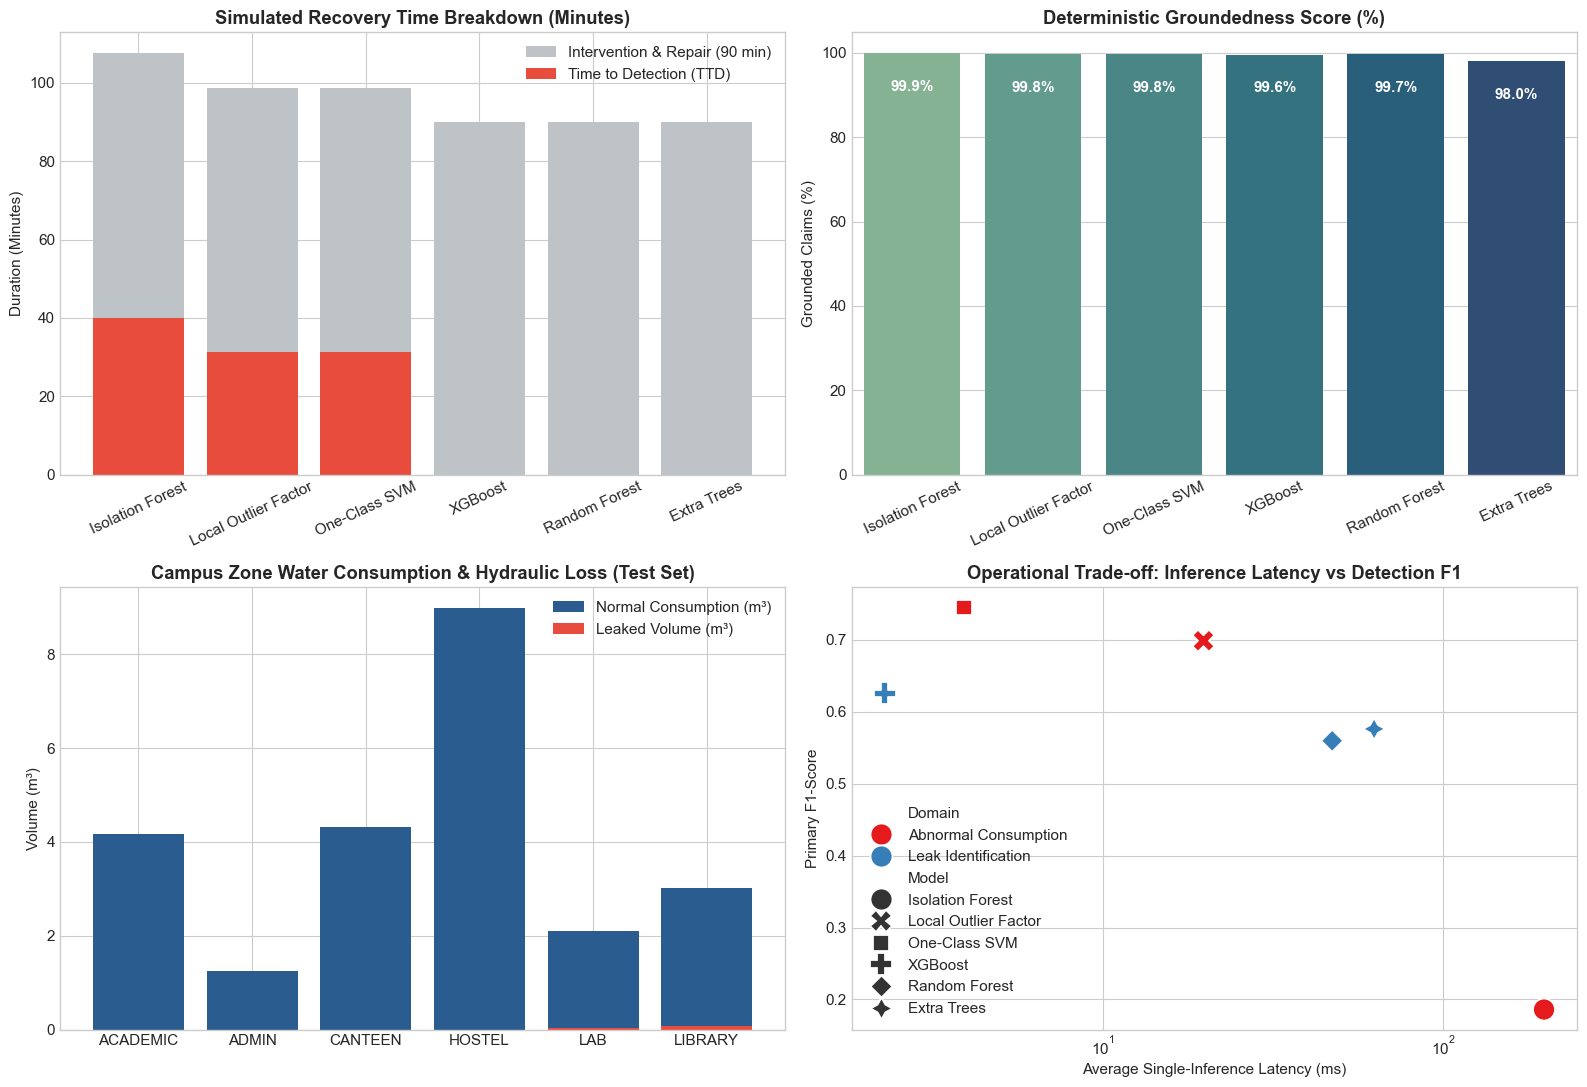

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Recovery Time Breakdown
rec_models = rec_summary['Model']
ttd = rec_summary['Time to Detection (min)']
tot = rec_summary['Total Recovery Time (min)']
axes[0, 0].bar(rec_models, tot, label='Intervention & Repair (90 min)', color='#bdc3c7')
axes[0, 0].bar(rec_models, ttd, label='Time to Detection (TTD)', color='#e74c3c')
axes[0, 0].set_title("Simulated Recovery Time Breakdown (Minutes)", fontweight='bold')
axes[0, 0].set_ylabel("Duration (Minutes)")
axes[0, 0].tick_params(axis='x', rotation=25)
axes[0, 0].legend()

# 2. Groundedness by Model
g_names = list(groundedness_results.keys())
g_vals = [groundedness_results[m] * 100 for m in g_names]
sns.barplot(x=g_names, y=g_vals, ax=axes[0, 1], palette='crest')
axes[0, 1].set_title("Deterministic Groundedness Score (%)", fontweight='bold')
axes[0, 1].set_ylabel("Grounded Claims (%)")
axes[0, 1].tick_params(axis='x', rotation=25)
for p in axes[0, 1].patches:
    axes[0, 1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2., p.get_height() - 8),
                         ha='center', va='center', color='white', fontweight='bold')

# 3. Zone-Wise Water Loss Breakdown
zones = list(kpi_xgb['zone_consumption_m3'].keys())
cons = [kpi_xgb['zone_consumption_m3'][z] for z in zones]
loss = [kpi_xgb['zone_leak_loss_m3'].get(z, 0.0) for z in zones]
axes[1, 0].bar(zones, cons, label='Normal Consumption (m³)', color='#2b5c8f')
axes[1, 0].bar(zones, loss, label='Leaked Volume (m³)', color='#e74c3c')
axes[1, 0].set_title("Campus Zone Water Consumption & Hydraulic Loss (Test Set)", fontweight='bold')
axes[1, 0].set_ylabel("Volume (m³)")
axes[1, 0].legend()

# 4. Latency vs F1 Score Trade-Off
sns.scatterplot(x='Avg Latency (ms)', y='Primary F1', hue='Domain', style='Model', s=250, data=df_operational, ax=axes[1, 1], palette='Set1')
axes[1, 1].set_title("Operational Trade-off: Inference Latency vs Detection F1", fontweight='bold')
axes[1, 1].set_xlabel("Average Single-Inference Latency (ms)")
axes[1, 1].set_ylabel("Primary F1-Score")
axes[1, 1].set_xscale('log')

plt.tight_layout()
fig_path = '../results/figures/05_operational_kpis.png' if os.path.exists('../results') else 'results/figures/05_operational_kpis.png'
plt.savefig(fig_path, dpi=300)
plt.show()
